# TRUSTSR Lab 04.02 — Uncertainty-Aware Recovery and Abstention

**Phase:** Lab 04 — Recovery-policy evaluation  
**Status:** Synthetic simulation | Version 1.0.0

## Research question
Can a recovery policy make safer decisions when it does **not know which dependency edges are missing**?

Lab 04.01 used an oracle-like list of omitted edges for its conservative policy. This lab removes that unrealistic advantage. Policies receive only:
- the observed dependency graph,
- known compromised source nodes,
- a per-node telemetry coverage signal in the range [0, 1].

The simulator retains hidden ground truth only for evaluation.

## Precisely defined policies
1. **Observed reachability:** quarantine nodes reachable from known compromised sources in the observed graph.
2. **Uncertainty-threshold policy:** quarantine observed-reachable nodes plus nodes whose telemetry coverage is below a configurable threshold. This does not claim to infer the true missing edges; it conservatively abstains on low-coverage nodes.
3. **Full quarantine:** quarantine every node as a safety-first reference.

A node is flagged as *potentially contaminated* by the threshold policy when its telemetry coverage is below the threshold. These labels express policy decisions, not verified ground truth.

## Evidence boundary
All graphs, compromises, coverage values, and results are synthetic. This notebook is not a real-agent experiment and does not establish production effectiveness or security guarantees.

## 1. Configuration

In [1]:
import random, sys, platform
from collections import defaultdict, deque
from datetime import datetime, timezone
import pandas as pd
import matplotlib.pyplot as plt

SEED = 20261012
N_TRIALS = 250
N_NODES = 50
EDGE_PROBABILITY = 0.06
MISSING_EDGE_RATES = [0.0, 0.1, 0.25, 0.4]
COVERAGE_THRESHOLDS = [0.50, 0.70, 0.85]
COVERAGE_NOISE = 0.20
N_COMPROMISED_SOURCES = 2

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("Execution UTC:", datetime.now(timezone.utc).isoformat())
print("Evidence classification: synthetic simulation only")
print({"seed": SEED, "trials": N_TRIALS, "nodes": N_NODES,
       "edge_probability": EDGE_PROBABILITY, "missing_edge_rates": MISSING_EDGE_RATES,
       "coverage_thresholds": COVERAGE_THRESHOLDS, "coverage_noise": COVERAGE_NOISE})

Python: 3.12.3
Platform: Linux-6.18.44-fc-v114-x86_64-with-glibc2.39
Execution UTC: 2026-10-11T10:26:39.951305+00:00
Evidence classification: synthetic simulation only
{'seed': 20261012, 'trials': 250, 'nodes': 50, 'edge_probability': 0.06, 'missing_edge_rates': [0.0, 0.1, 0.25, 0.4], 'coverage_thresholds': [0.5, 0.7, 0.85], 'coverage_noise': 0.2}


## 2. Helpers: ground truth, observed graph, and coverage signal

In [2]:
def make_dag(rng, n_nodes, edge_probability):
    nodes = [f"S{i:02d}" for i in range(n_nodes)]
    edges = [(nodes[i], nodes[j]) for i in range(n_nodes) for j in range(i+1, n_nodes)
             if rng.random() < edge_probability]
    return nodes, edges

def reachable(nodes, edges, sources):
    adj = defaultdict(list)
    for u, v in edges:
        adj[u].append(v)
    seen = set(sources)
    queue = deque(sources)
    while queue:
        u = queue.popleft()
        for v in adj[u]:
            if v not in seen:
                seen.add(v)
                queue.append(v)
    return seen

def observe_edges(rng, true_edges, missing_rate):
    observed, hidden = [], []
    for edge in true_edges:
        (hidden if rng.random() < missing_rate else observed).append(edge)
    return observed, hidden

def generate_coverage(rng, nodes, true_edges, observed_edges, noise):
    # Synthetic telemetry coverage: fraction of true incident edges that were observed.
    # Isolated nodes receive coverage 1.0. Noise perturbs the value, then clips to [0,1].
    incident_true = {n: 0 for n in nodes}
    incident_seen = {n: 0 for n in nodes}
    for u, v in true_edges:
        incident_true[u] += 1
        incident_true[v] += 1
    for u, v in observed_edges:
        incident_seen[u] += 1
        incident_seen[v] += 1
    coverage = {}
    for n in nodes:
        base = incident_seen[n] / incident_true[n] if incident_true[n] else 1.0
        coverage[n] = min(1.0, max(0.0, base + rng.uniform(-noise, noise)))
    return coverage

def classify_policy(nodes, observed_edges, sources, coverage, threshold):
    confirmed_by_observed_graph = reachable(nodes, observed_edges, sources)
    low_coverage = {n for n in nodes if coverage[n] < threshold}
    potentially_contaminated = low_coverage - confirmed_by_observed_graph
    quarantined = confirmed_by_observed_graph | low_coverage
    return confirmed_by_observed_graph, potentially_contaminated, quarantined

def metrics(nodes, truth, quarantined):
    clean = set(nodes) - set(truth)
    fn = set(truth) - set(quarantined)
    fp = clean & set(quarantined)
    preserved = clean - set(quarantined)
    return {
        "truth_contaminated": len(truth), "truth_clean": len(clean),
        "quarantined": len(quarantined), "false_negatives": len(fn),
        "false_negative_rate": len(fn)/len(truth) if truth else 0.0,
        "false_positives": len(fp), "false_positive_rate": len(fp)/len(clean) if clean else 0.0,
        "clean_preserved": len(preserved),
        "clean_preservation_rate": len(preserved)/len(clean) if clean else 0.0,
        "quarantine_blast_radius": len(quarantined)/len(nodes)
    }

print("Helpers defined.")

Helpers defined.


## 3. Run paired synthetic trials

In [3]:
trial_rows, node_rows = [], []
for missing_rate in MISSING_EDGE_RATES:
    for trial in range(N_TRIALS):
        trial_seed = SEED + int(missing_rate * 10000) * 1000 + trial
        rng = random.Random(trial_seed)
        nodes, true_edges = make_dag(rng, N_NODES, EDGE_PROBABILITY)
        sources = set(rng.sample(nodes[:max(3, N_NODES//4)], N_COMPROMISED_SOURCES))
        truth = reachable(nodes, true_edges, sources)
        observed_edges, hidden_edges = observe_edges(rng, true_edges, missing_rate)
        coverage_rng = random.Random(trial_seed + 987654)
        coverage = generate_coverage(coverage_rng, nodes, true_edges, observed_edges, COVERAGE_NOISE)
        observed_pred = reachable(nodes, observed_edges, sources)

        policies = {
            "full_quarantine": set(nodes),
            "observed_reachability": observed_pred
        }
        policy_labels = {
            "full_quarantine": (set(nodes), set()),
            "observed_reachability": (observed_pred, set())
        }
        for threshold in COVERAGE_THRESHOLDS:
            _, potential, quarantined = classify_policy(nodes, observed_edges, sources, coverage, threshold)
            policy = f"coverage_threshold_{threshold:.2f}"
            policies[policy] = quarantined
            policy_labels[policy] = (reachable(nodes, observed_edges, sources), potential)

        for policy, quarantine in policies.items():
            m = metrics(nodes, truth, quarantine)
            trial_rows.append({
                "missing_edge_rate": missing_rate, "trial": trial, "policy": policy,
                "threshold": float(policy.rsplit("_", 1)[-1]) if policy.startswith("coverage_threshold") else None,
                "node_count": N_NODES, "true_edge_count": len(true_edges),
                "observed_edge_count": len(observed_edges), "hidden_edge_count": len(hidden_edges),
                "compromised_sources": ";".join(sorted(sources)), **m
            })
            confirmed, potential = policy_labels[policy]
            for node in nodes:
                if node in confirmed:
                    label = "confirmed_contaminated_by_observed_graph"
                elif node in potential:
                    label = "potentially_contaminated_low_coverage"
                elif node in quarantine:
                    label = "quarantined_other_policy_rule"
                else:
                    label = "not_flagged_by_policy"
                node_rows.append({
                    "missing_edge_rate": missing_rate, "trial": trial, "policy": policy,
                    "node": node, "coverage_signal": coverage[node],
                    "ground_truth_contaminated": node in truth,
                    "quarantined": node in quarantine, "policy_label": label
                })

trial_df = pd.DataFrame(trial_rows)
node_df = pd.DataFrame(node_rows)
expected_policies = 2 + len(COVERAGE_THRESHOLDS)
assert len(trial_df) == len(MISSING_EDGE_RATES) * N_TRIALS * expected_policies
assert len(node_df) == len(MISSING_EDGE_RATES) * N_TRIALS * expected_policies * N_NODES
assert trial_df["false_negative_rate"].between(0, 1).all()
assert trial_df["false_positive_rate"].between(0, 1).all()
assert node_df["coverage_signal"].between(0, 1).all()
print("Trials per missing-edge condition:", N_TRIALS)
print("Policy evaluations:", len(trial_df))
print("Node-level classifications:", len(node_df))
print("Paired-trial structure assertions passed.")
display(trial_df.head())

Trials per missing-edge condition: 250
Policy evaluations: 5000
Node-level classifications: 250000
Paired-trial structure assertions passed.


   missing_edge_rate  trial                   policy  threshold  node_count  true_edge_count  observed_edge_count  hidden_edge_count compromised_sources  truth_contaminated  truth_clean  \
0                0.0      0          full_quarantine        NaN          50               63                   63                  0             S05;S09                  17           33   
1                0.0      0    observed_reachability        NaN          50               63                   63                  0             S05;S09                  17           33   
2                0.0      0  coverage_threshold_0.50       0.50          50               63                   63                  0             S05;S09                  17           33   
3                0.0      0  coverage_threshold_0.70       0.70          50               63                   63                  0             S05;S09                  17           33   
4                0.0      0  coverage_threshold_0.85   

## 4. Aggregate results and evaluate calibration/abstention trade-offs

In [4]:
METRICS = ["false_negative_rate", "false_positive_rate", "clean_preservation_rate",
           "quarantine_blast_radius", "false_negatives", "false_positives", "quarantined"]
aggregate_df = trial_df.groupby(["missing_edge_rate", "policy"])[METRICS].agg(["mean", "std"]).reset_index()
aggregate_df.columns = ["_".join(str(x) for x in col if str(x) != "").rstrip("_")
                        if isinstance(col, tuple) else col for col in aggregate_df.columns]
display(aggregate_df)

# Policies must be monotone in threshold: a higher threshold cannot quarantine fewer nodes
# in the same trial because it can only add low-coverage nodes.
for rate in MISSING_EDGE_RATES:
    for trial in range(N_TRIALS):
        subset = trial_df[(trial_df["missing_edge_rate"] == rate) & (trial_df["trial"] == trial)]
        q = subset.set_index("policy")["quarantined"]
        assert q["coverage_threshold_0.85"] >= q["coverage_threshold_0.70"]
        assert q["coverage_threshold_0.70"] >= q["coverage_threshold_0.50"]
        assert q["full_quarantine"] == N_NODES

# Complete observed graph: observed reachability must match truth for this propagation model.
complete = trial_df[(trial_df["missing_edge_rate"] == 0.0) &
                    (trial_df["policy"] == "observed_reachability")]
assert (complete["false_negatives"] == 0).all()
print("Monotonicity and complete-graph assertions passed.")

    missing_edge_rate                   policy  false_negative_rate_mean  false_negative_rate_std  false_positive_rate_mean  false_positive_rate_std  clean_preservation_rate_mean  \
0                0.00  coverage_threshold_0.50                  0.000000                 0.000000                  0.000000                 0.000000                      1.000000   
1                0.00  coverage_threshold_0.70                  0.000000                 0.000000                  0.000000                 0.000000                      1.000000   
2                0.00  coverage_threshold_0.85                  0.000000                 0.000000                  0.128460                 0.056759                      0.871540   
3                0.00          full_quarantine                  0.000000                 0.000000                  1.000000                 0.000000                      0.000000   
4                0.00    observed_reachability                  0.000000                 0

Monotonicity and complete-graph assertions passed.


## 5. Plot false-negative rate and operational cost

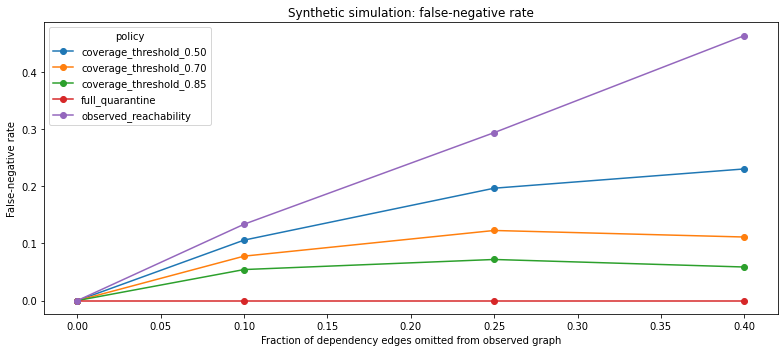

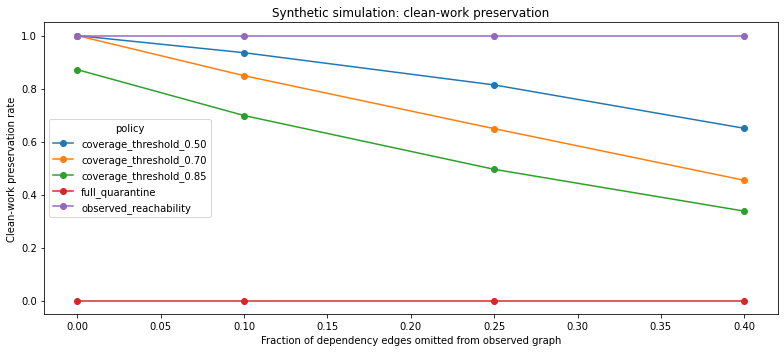

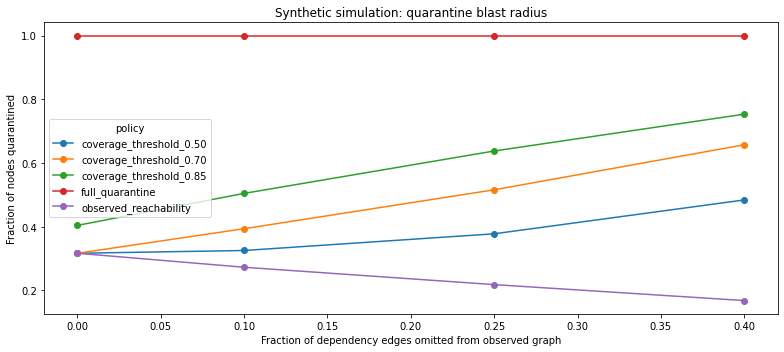

In [5]:
for metric, title, ylabel in [
    ("false_negative_rate", "Synthetic simulation: false-negative rate", "False-negative rate"),
    ("clean_preservation_rate", "Synthetic simulation: clean-work preservation", "Clean-work preservation rate"),
    ("quarantine_blast_radius", "Synthetic simulation: quarantine blast radius", "Fraction of nodes quarantined")
]:
    pivot = trial_df.groupby(["missing_edge_rate", "policy"])[metric].mean().unstack("policy")
    ax = pivot.plot(marker="o", figsize=(11, 5))
    ax.set_title(title)
    ax.set_xlabel("Fraction of dependency edges omitted from observed graph")
    ax.set_ylabel(ylabel)
    plt.tight_layout()
    plt.show()

## 6. Report measured synthetic findings without assuming superiority

In [6]:
summary_df = trial_df.groupby(["missing_edge_rate", "policy"])[
    ["false_negative_rate", "false_positive_rate", "clean_preservation_rate", "quarantine_blast_radius"]
].mean().reset_index()
display(summary_df)

for rate in MISSING_EDGE_RATES:
    print(f"Missing-edge rate {rate:.0%}")
    sub = summary_df[summary_df["missing_edge_rate"] == rate].set_index("policy")
    for policy in sub.index:
        row = sub.loc[policy]
        print(f"  {policy}: FN={row['false_negative_rate']:.3f}, "
              f"FP={row['false_positive_rate']:.3f}, "
              f"clean_preservation={row['clean_preservation_rate']:.3f}, "
              f"blast_radius={row['quarantine_blast_radius']:.3f}")

print("Interpret only the measured outputs above. All findings are synthetic simulation.")

    missing_edge_rate                   policy  false_negative_rate  false_positive_rate  clean_preservation_rate  quarantine_blast_radius
0                0.00  coverage_threshold_0.50             0.000000             0.000000                 1.000000                  0.31672
1                0.00  coverage_threshold_0.70             0.000000             0.000000                 1.000000                  0.31672
2                0.00  coverage_threshold_0.85             0.000000             0.128460                 0.871540                  0.40432
3                0.00          full_quarantine             0.000000             1.000000                 0.000000                  1.00000
4                0.00    observed_reachability             0.000000             0.000000                 1.000000                  0.31672
5                0.10  coverage_threshold_0.50             0.105789             0.064408                 0.935592                  0.32544
6                0.10  cove

Missing-edge rate 0%
  coverage_threshold_0.50: FN=0.000, FP=0.000, clean_preservation=1.000, blast_radius=0.317
  coverage_threshold_0.70: FN=0.000, FP=0.000, clean_preservation=1.000, blast_radius=0.317
  coverage_threshold_0.85: FN=0.000, FP=0.128, clean_preservation=0.872, blast_radius=0.404
  full_quarantine: FN=0.000, FP=1.000, clean_preservation=0.000, blast_radius=1.000
  observed_reachability: FN=0.000, FP=0.000, clean_preservation=1.000, blast_radius=0.317
Missing-edge rate 10%
  coverage_threshold_0.50: FN=0.106, FP=0.064, clean_preservation=0.936, blast_radius=0.325
  coverage_threshold_0.70: FN=0.078, FP=0.151, clean_preservation=0.849, blast_radius=0.394
  coverage_threshold_0.85: FN=0.054, FP=0.302, clean_preservation=0.698, blast_radius=0.505
  full_quarantine: FN=0.000, FP=1.000, clean_preservation=0.000, blast_radius=1.000
  observed_reachability: FN=0.134, FP=0.000, clean_preservation=1.000, blast_radius=0.273
Missing-edge rate 25%
  coverage_threshold_0.50: FN=0.197

## 7. Export reproducibility artifacts

In [7]:
trial_df.to_csv("trustsr_lab04_02_trial_results.csv", index=False)
node_df.to_csv("trustsr_lab04_02_node_classifications.csv", index=False)
aggregate_df.to_csv("trustsr_lab04_02_aggregate_metrics.csv", index=False)
summary_df.to_csv("trustsr_lab04_02_policy_summary.csv", index=False)

print("CSV exports created:")
for filename in [
    "trustsr_lab04_02_trial_results.csv",
    "trustsr_lab04_02_node_classifications.csv",
    "trustsr_lab04_02_aggregate_metrics.csv",
    "trustsr_lab04_02_policy_summary.csv"
]:
    print("-", filename)

CSV exports created:
- trustsr_lab04_02_trial_results.csv
- trustsr_lab04_02_node_classifications.csv
- trustsr_lab04_02_aggregate_metrics.csv
- trustsr_lab04_02_policy_summary.csv


## 8. Interpretation and limitations

### What is tested
The threshold policy does not receive the hidden list of omitted edges. It receives only a synthetic node-level telemetry coverage signal and a threshold. It abstains by quarantining low-coverage nodes.

### Important limitation
The coverage signal is computed from the simulator's true and observed incident-edge counts, then perturbed by noise. A real deployment may not know the true incident-edge count, so this remains a synthetic proxy—not a validated telemetry-calibration method.

### Reporting rule
Report false-negative rate together with false-positive rate, clean-work preservation, and quarantine blast radius. A reduction in false negatives alone is not enough to establish that a policy is better.

**Required wording:** “This experiment evaluates uncertainty-threshold quarantine policies in a synthetic directed-acyclic graph model. The results are conditional on the generated graph distribution and synthetic coverage proxy; they do not establish real-world security or recovery effectiveness.”

### Next step
Run all cells, inspect assertions and CSV exports, then upload the executed PDF. Do not claim the uncertainty-aware policy is superior until the measured trade-offs and the limitations of the coverage signal have been reviewed.